## Monster × VIDEO CDFS reference catalogue

I construct a reusable HTM7 reference catalogue for the VIDEO CDFS field, independent of a particular Rubin data release. The catalogue retains Monster astrometry and optical reference photometry and supplies the VIRCAM bands through the VIDEO DR5 calibration.

- **VIRCAM Z and Y:** calculate reference fluxes from Monster DES photometry using `Monster_to_VIDEO_band_z.yaml` and `Monster_to_VIDEO_band_y.yaml`. These transformations were fitted using aperture-corrected ESO VIDEO photometry.
- **VIRCAM J, H, and Ks:** use ESO DR5 single-band `APERMAG3` and `APERMAG3ERR` (aperture-corrected AB magnitudes), associated with the VIDEO band-merged catalogue by secure positional and photometric matching.
- **Monster optical u, g, r, i, z, y:** retain the original `monster_ComCam_*` fluxes and uncertainties unchanged, in nJy. These are kept for reference-catalogue compatibility; their suitability for a particular instrument/filter system must be checked when configuring a pipeline run.
- **Astrometry:** preserve Monster IDs, coordinates, proper motions and astrometric metadata. Propagate Monster positions to the VIDEO epoch for matching only.

I use the CDFS VIDEO matching epoch of **2008.9**, established from the earlier CDFS epoch tests. Z/Y transformations are not extrapolated beyond their calibrated colour intervals. The output keeps the established optical and VIRCAM reference field names and records the Monster–VIDEO match separation. Unavailable photometry is stored as NaN.

I validate the ESO source associations, inspect the fitted colour transformations, check the output schema and preserved optical data, and generate a Butler HTM7 ingest table. No cross-method comparison or processing-run-specific operations are required.

### Imports

In [1]:
from pathlib import Path

import numpy as np
import astropy.units as u
import matplotlib.pyplot as plt
import yaml

from astropy.coordinates import SkyCoord, match_coordinates_sky
from astropy.io import fits
from astropy.table import Table
from astropy.time import Time

from scipy.interpolate import CubicSpline

import lsst.afw.table as afwTable
from lsst.geom import SpherePoint, radians

### Input and output configuration
I run this notebook from `dmu2/Monster/`. The Monster CDFS HTM7 shards are in `data/the_monster_20250219/CDFS/`, the VIDEO DR5 merged and individual-band catalogues are in `data/VIDEO/`, and both colour-transformation YAML files are beside this notebook. The input-shard list is discovered from the CDFS directory so it can be used for future processing without hardcoded shard IDs.
The reference catalogue is written to `data/video_cdfs/the_monster_20250219_vista/`. Existing FITS shards are **not overwritten**: move or archive an earlier output before rerunning the build cell. I validate inputs before any shard is written.

In [2]:
# Paths relative to the notebook working directory: dmu2/Monster/
monster_dir = Path("data/the_monster_20250219/CDFS")
video_dir = Path("data/VIDEO")
vista_file = video_dir / "video-cdfs-dr5.fits"
ESO_DIR = video_dir

calibration_dir = Path(".")
z_yaml = calibration_dir / "Monster_to_VIDEO_band_z.yaml"
y_yaml = calibration_dir / "Monster_to_VIDEO_band_y.yaml"

outdir = Path("data/video_cdfs/the_monster_20250219_vista")

if not monster_dir.is_dir():
    raise FileNotFoundError(f"Monster CDFS shard directory not found: {monster_dir}")

monster_files = sorted(monster_dir.glob("refcat_htm7_*.fits"))
if not monster_files:
    raise FileNotFoundError(f"No Monster HTM7 shards found in {monster_dir}")

try:
    htm7_ids = [int(path.stem.split("_")[-1]) for path in monster_files]
except ValueError as exc:
    raise ValueError("Unrecognised Monster HTM7 shard filename") from exc

if len(htm7_ids) != len(set(htm7_ids)):
    raise RuntimeError("Duplicate HTM7 shard IDs found in CDFS inputs")

monster_path_by_id = dict(zip(htm7_ids, monster_files))

for path in (vista_file, z_yaml, y_yaml):
    if not path.is_file():
        raise FileNotFoundError(path)

outdir.mkdir(parents=True, exist_ok=True)

print(f"Monster CDFS HTM7 shards: {len(htm7_ids)}")
print("HTM7 IDs:", htm7_ids)
print("VIDEO CDFS merged catalogue:", vista_file)
print("VIDEO single-band directory:", ESO_DIR)
print("Z transformation:", z_yaml)
print("Y transformation:", y_yaml)
print("Output directory:", outdir)

Monster CDFS HTM7 shards: 32
HTM7 IDs: [147028, 147042, 147048, 147049, 147050, 147051, 147052, 147053, 147055, 147056, 147057, 147059, 147144, 147169, 147170, 147171, 147172, 147173, 147174, 147175, 147177, 147178, 147179, 147180, 147181, 147182, 147183, 147185, 147188, 147190, 147191, 147198]
VIDEO CDFS merged catalogue: data/VIDEO/video-cdfs-dr5.fits
VIDEO single-band directory: data/VIDEO
Z transformation: Monster_to_VIDEO_band_z.yaml
Y transformation: Monster_to_VIDEO_band_y.yaml
Output directory: data/video_cdfs/the_monster_20250219_vista


### Load and validate the Z/Y calibration YAML files

The VIDEO Z/Y calibrations store a colour-dependent flux ratio, derived from aperture-corrected ESO DR5 measurements.

For Z,

$$
R_Z(i-z)
=
\frac{F_{{\rm DES},z}}
     {F_{{\rm VIRCAM},Z}},
$$

and therefore

$$
F_{{\rm VIRCAM},Z}
=
\frac{F_{{\rm DES},z}}
     {R_Z(i-z)}.
$$

For Y,

$$
R_Y(z-y)
=
\frac{F_{{\rm DES},y}}
     {F_{{\rm VIRCAM},Y}},
$$

and therefore

$$
F_{{\rm VIRCAM},Y}
=
\frac{F_{{\rm DES},y}}
     {R_Y(z-y)}.
$$

The validation below is intentionally strict. In particular,
it verifies that the VIDEO Z and Y transformations use the
correct Monster DES source fluxes and colour definitions,
and that both spline relations are positive and valid
over their calibrated colour intervals.

In [3]:
with z_yaml.open() as stream:
    z_payload = yaml.safe_load(
        stream
    )

with y_yaml.open() as stream:
    y_payload = yaml.safe_load(
        stream
    )


EXPECTED_TRANSFORMS = {
    "Z": {
        "source_survey": "Monster",
        "target_survey": "VISTA",
        "source_field": "monster_DES_z_flux",
        "source_color_field_1": "monster_DES_i_flux",
        "source_color_field_2": "monster_DES_z_flux",
    },
    "Y": {
        "source_survey": "Monster",
        "target_survey": "VISTA",
        "source_field": "monster_DES_y_flux",
        "source_color_field_1": "monster_DES_z_flux",
        "source_color_field_2": "monster_DES_y_flux",
    },
}


def validate_transform_yaml(
    payload,
    expected,
    band,
):
    """Validate a Monster-to-VISTA calibration YAML."""

    required_keys = [
        "flux_offset",
        "nodes",
        "spline_values",
        "source_field",
        "source_color_field_1",
        "source_color_field_2",
        "source_survey",
        "target_survey",
    ]

    missing = [
        key
        for key in required_keys
        if key not in payload
    ]

    if missing:
        raise KeyError(
            f"{band} YAML is missing keys: "
            + ", ".join(
                missing
            )
        )

    for key, expected_value in expected.items():

        actual_value = payload[
            key
        ]

        if actual_value != expected_value:
            raise ValueError(
                f"{band} YAML: {key} = "
                f"{actual_value!r}, expected "
                f"{expected_value!r}"
            )

    flux_offset = float(
        payload[
            "flux_offset"
        ]
    )

    if flux_offset != 0.0:
        raise NotImplementedError(
            f"{band} YAML has non-zero flux_offset="
            f"{flux_offset}. This notebook implements "
            "the current zero-offset calibration only."
        )

    nodes = np.asarray(
        payload[
            "nodes"
        ],
        dtype=float,
    )

    values = np.asarray(
        payload[
            "spline_values"
        ],
        dtype=float,
    )

    if (
        nodes.ndim != 1
        or values.ndim != 1
        or len(nodes) != len(values)
        or len(nodes) < 2
    ):
        raise ValueError(
            f"{band} YAML nodes/spline_values "
            "have incompatible shapes."
        )

    if (
        not np.all(
            np.isfinite(
                nodes
            )
        )
        or not np.all(
            np.isfinite(
                values
            )
        )
    ):
        raise ValueError(
            f"{band} YAML contains non-finite "
            "nodes or spline values."
        )

    if not np.all(
        np.diff(
            nodes
        )
        > 0
    ):
        raise ValueError(
            f"{band} YAML nodes must be "
            "strictly increasing."
        )

    if not np.all(
        values > 0
    ):
        raise ValueError(
            f"{band} YAML contains non-positive "
            "flux-ratio values."
        )

    spline = CubicSpline(
        nodes,
        values,
        extrapolate=False,
    )

    return {
        "payload": payload,
        "nodes": nodes,
        "values": values,
        "spline": spline,
        "color_min": float(
            nodes[0]
        ),
        "color_max": float(
            nodes[-1]
        ),
    }


z_transform = validate_transform_yaml(
    z_payload,
    EXPECTED_TRANSFORMS["Z"],
    "Z",
)

y_transform = validate_transform_yaml(
    y_payload,
    EXPECTED_TRANSFORMS["Y"],
    "Y",
)

print("Validated Z transformation:")
print(
    "  source flux : "
    f"{z_payload['source_field']}"
)
print(
    "  colour      : "
    f"{z_payload['source_color_field_1']} - "
    f"{z_payload['source_color_field_2']}"
)
print(
    "  colour range: "
    f"{z_transform['color_min']:.4f} "
    f"to {z_transform['color_max']:.4f} mag"
)

print("\nValidated Y transformation:")
print(
    "  source flux : "
    f"{y_payload['source_field']}"
)
print(
    "  colour      : "
    f"{y_payload['source_color_field_1']} - "
    f"{y_payload['source_color_field_2']}"
)
print(
    "  colour range: "
    f"{y_transform['color_min']:.4f} "
    f"to {y_transform['color_max']:.4f} mag"
)

# Pin the calibrated YAML coefficients used for this reference build.
# Update this fingerprint intentionally if the calibrations are refitted.
EXPECTED_FIRST_SPLINE_NODE = {"Z": 0.9003024975005498, "Y": 0.9034930255048785}
for band, transform in [("Z", z_transform), ("Y", y_transform)]:
    expected = EXPECTED_FIRST_SPLINE_NODE[band]
    observed = float(transform["values"][0])
    if not np.isclose(observed, expected, rtol=0, atol=1e-8):
        raise RuntimeError(
            f"{band} YAML does not match the expected calibration version: "
            f"first node {observed:.10f} != {expected:.10f}"
        )
print("Validated VIDEO Z/Y YAML coefficient fingerprints.")


Validated Z transformation:
  source flux : monster_DES_z_flux
  colour      : monster_DES_i_flux - monster_DES_z_flux
  colour range: 0.0000 to 0.6500 mag

Validated Y transformation:
  source flux : monster_DES_y_flux
  colour      : monster_DES_z_flux - monster_DES_y_flux
  colour range: -0.0500 to 0.1750 mag
Validated VIDEO Z/Y YAML coefficient fingerprints.


### Inspect the stored Z transformation

The points are the stored YAML node values and the line is the cubic interpolation used by this notebook. Extrapolation is disabled.

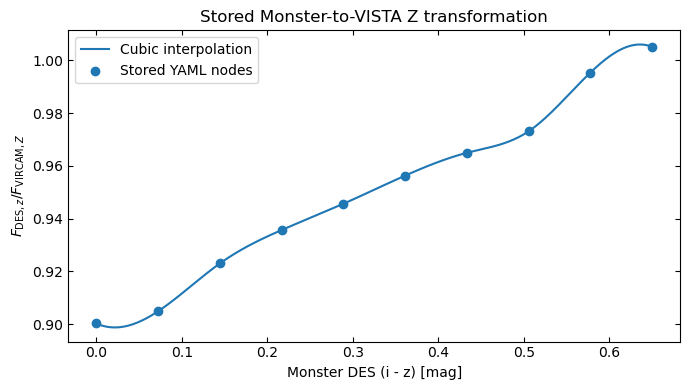

In [4]:
z_grid = np.linspace(
    z_transform[
        "color_min"
    ],
    z_transform[
        "color_max"
    ],
    500,
)

fig, ax = plt.subplots(
    figsize=(7, 4)
)

ax.plot(
    z_grid,
    z_transform[
        "spline"
    ](
        z_grid
    ),
    label="Cubic interpolation",
)

ax.scatter(
    z_transform[
        "nodes"
    ],
    z_transform[
        "values"
    ],
    label="Stored YAML nodes",
)

ax.set_xlabel(
    "Monster DES (i - z) [mag]"
)
ax.set_ylabel(
    r"$F_{\mathrm{DES},z}/F_{\mathrm{VIRCAM},Z}$"
)
ax.set_title(
    "Stored Monster-to-VISTA Z transformation"
)
ax.tick_params(
    direction="in",
    top=True,
    right=True,
)
ax.legend()

plt.tight_layout()
plt.show()

### Inspect the stored Y transformation

The Y transformation uses DES $y$ as the source flux and DES $z-y$ as the colour:

$$
z-y
=
-2.5\log_{10}
\left(
\frac{F_{{\rm DES},z}}
     {F_{{\rm DES},y}}
\right).
$$

Its calibrated colour interval is much narrower than the Z interval. No value outside the stored Y node range is accepted later in the notebook.

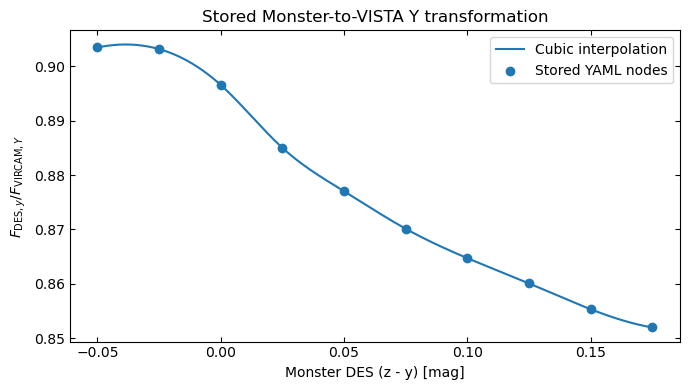

In [5]:
y_grid = np.linspace(
    y_transform[
        "color_min"
    ],
    y_transform[
        "color_max"
    ],
    500,
)

fig, ax = plt.subplots(
    figsize=(7, 4)
)

ax.plot(
    y_grid,
    y_transform[
        "spline"
    ](
        y_grid
    ),
    label="Cubic interpolation",
)

ax.scatter(
    y_transform[
        "nodes"
    ],
    y_transform[
        "values"
    ],
    label="Stored YAML nodes",
)

ax.set_xlabel(
    "Monster DES (z - y) [mag]"
)
ax.set_ylabel(
    r"$F_{\mathrm{DES},y}/F_{\mathrm{VIRCAM},Y}$"
)
ax.set_title(
    "Stored Monster-to-VISTA Y transformation"
)
ax.tick_params(
    direction="in",
    top=True,
    right=True,
)
ax.legend()

plt.tight_layout()
plt.show()

### Define the VIDEO J/H/Ks input catalogues
The VIDEO DR5 band-merged catalogue supplies source positions, original `MAG_APER_2` measurements and quality flags for the cross-match and identity checks. The reference fluxes for J/H/Ks come exclusively from the ESO DR5 single-band **aperture-corrected** `APERMAG3` measurements and their errors, converted from AB magnitudes directly to nJy. The original merged-catalogue fluxes are not used for the output photometry.

In [6]:
# Output reference fields for the three directly calibrated bands.
# The merged catalogue's original aperture *magnitudes* are used only
# for association and quality audits, not for output fluxes.
JHK_OUTPUT_FIELDS = (
    "j_flux", "j_fluxErr",
    "h_flux", "h_fluxErr",
    "ks_flux", "ks_fluxErr",
)

# ESO DR5 single-band aperture-corrected photometry (three CDFS tiles).
ESO_JHK_FILES = {
    "J": [ESO_DIR / f"J-CDFS{i}.fits" for i in (1, 2, 3)],
    "H": [ESO_DIR / f"H-CDFS{i}.fits" for i in (1, 2, 3)],
    "Ks": [ESO_DIR / f"K-CDFS{i}.fits" for i in (1, 2, 3)],
}
EXPECTED_FILTERID = {"J": 3, "H": 4, "Ks": 5}
required_eso_columns = {
    "OBJID", "RA", "DEC", "FILTERID", "APERMAG3", "APERMAG3ERR",
    "APERMAGNOAPERCORR3", "ERRBITS",
}
print("ESO DR5 CDFS J/H/Ks catalogues (aperture-corrected)")
for band, paths in ESO_JHK_FILES.items():
    for path in paths:
        if not path.is_file():
            raise FileNotFoundError(f"Missing {band} catalogue: {path}")
        with fits.open(path, memmap=True) as hdul:
            hdu = hdul[1]
            missing = required_eso_columns - set(hdu.columns.names)
            if missing:
                raise KeyError(f"{path.name}: missing {missing}")
            filters = np.unique(hdu.data["FILTERID"])
            if len(filters) != 1 or int(filters[0]) != EXPECTED_FILTERID[band]:
                raise ValueError(f"{path.name}: unexpected FILTERID {filters}")
            ids = np.asarray(hdu.data["OBJID"])
            if len(np.unique(ids)) != len(ids):
                raise ValueError(f"{path.name}: duplicate OBJID values")
            print(f"  {band:2s} {path.name:16s} N={len(ids):,} FILTERID={int(filters[0])}")
print("All nine ESO J/H/Ks catalogues verified.")


ESO DR5 CDFS J/H/Ks catalogues (aperture-corrected)
  J  J-CDFS1.fits     N=295,791 FILTERID=3
  J  J-CDFS2.fits     N=315,348 FILTERID=3
  J  J-CDFS3.fits     N=295,093 FILTERID=3
  H  H-CDFS1.fits     N=251,934 FILTERID=4
  H  H-CDFS2.fits     N=278,487 FILTERID=4
  H  H-CDFS3.fits     N=266,895 FILTERID=4
  Ks K-CDFS1.fits     N=235,941 FILTERID=5
  Ks K-CDFS2.fits     N=228,487 FILTERID=5
  Ks K-CDFS3.fits     N=227,617 FILTERID=5
All nine ESO J/H/Ks catalogues verified.


### Load the required VIDEO merged-catalogue columns
I retain VIDEO source positions (`RA2000`, `DEC2000`) for Monster matching. For J/H/Ks, the native band-detection coordinates and original uncorrected `MAG_APER_2` values are used for secure association with ESO single-band sources. The original flux columns are not needed because only the aperture-corrected ESO magnitudes determine the final J/H/Ks reference fluxes.

In [7]:
band_match_cols = []

for prefix in ["J", "H", "KS"]:
    band_match_cols.extend([
        f"{prefix}_ALPHA_J2000",
        f"{prefix}_DELTA_J2000",
        f"{prefix}_MAG_APER_2",
        f"{prefix}_MAGERR_APER_2",
        f"{prefix}_FLAGS",
    ])

required_vista_cols = (
    ["RA2000", "DEC2000", "KS_CLASS_STAR"]
    + band_match_cols
)

with fits.open(
    vista_file,
    memmap=True,
) as hdul:

    table_hdu = next(
        (
            hdu
            for hdu in hdul
            if isinstance(
                hdu,
                fits.BinTableHDU,
            )
            and hdu.data is not None
        ),
        None,
    )

    if table_hdu is None:
        raise RuntimeError(
            f"No binary-table HDU found in {vista_file}"
        )

    available_cols = set(
        table_hdu.columns.names
    )

    missing_vista_cols = [
        name
        for name in required_vista_cols
        if name not in available_cols
    ]

    if missing_vista_cols:
        raise KeyError(
            "Missing VIDEO columns: "
            + ", ".join(
                missing_vista_cols
            )
        )

    vista = Table(
        {
            name: np.array(
                table_hdu.data[
                    name
                ],
                copy=True,
            )
            for name
            in required_vista_cols
        }
    )

finite_coord = (
    np.isfinite(
        np.asarray(
            vista[
                "RA2000"
            ],
            dtype=float,
        )
    )
    & np.isfinite(
        np.asarray(
            vista[
                "DEC2000"
            ],
            dtype=float,
        )
    )
)

vista = vista[
    finite_coord
]

vis_coords = SkyCoord(
    ra=np.asarray(
        vista[
            "RA2000"
        ],
        dtype=float,
    ) * u.deg,
    dec=np.asarray(
        vista[
            "DEC2000"
        ],
        dtype=float,
    ) * u.deg,
)

print(
    f"VIDEO CDFS rows retained: "
    f"{len(vista):,}"
)
print(
    f"VIDEO columns retained: "
    f"{len(vista.colnames)}"
)

VIDEO CDFS rows retained: 1,138,485
VIDEO columns retained: 18


### Matching configuration
The CDFS VIDEO effective epoch is **2008.9** (Julian year), based on the earlier CDFS matching-epoch tests. Monster positions are propagated using proper motions for matching only. Gold Monster–VIDEO matches require mutual nearest neighbours within 0.5 arcsec and Monster-side isolation beyond 1 arcsec. Native Monster astrometry remains unchanged in the output.

In [8]:
VIDEO_EPOCH_JYEAR = 2008.9

MJD_VIDEO = Time(
    VIDEO_EPOCH_JYEAR,
    format="jyear",
).mjd

MATCH_RADIUS = (
    0.5
    * u.arcsec
)

ISO_MIN_SEP = (
    1.0
    * u.arcsec
)

VISTA_MARGIN_DEG = 0.6

print(
    f"VIDEO_EPOCH_JYEAR = "
    f"{VIDEO_EPOCH_JYEAR:.2f}"
)
print(
    f"MJD_VIDEO         = "
    f"{MJD_VIDEO:.2f}"
)
print(
    f"MATCH_RADIUS      = "
    f"{MATCH_RADIUS}"
)
print(
    f"ISO_MIN_SEP       = "
    f"{ISO_MIN_SEP}"
)

VIDEO_EPOCH_JYEAR = 2008.90
MJD_VIDEO         = 54795.23
MATCH_RADIUS      = 0.5 arcsec
ISO_MIN_SEP       = 1.0 arcsec


### Matching helper functions
I use the same local VIDEO selection, proper-motion propagation, mutual nearest-neighbour and isolation procedures as in the ELAIS-S1 reference-building workflow, with the CDFS-specific input positions and matching epoch.

In [9]:
def local_vista_cut(
    ra_deg,
    dec_deg,
    margin_deg=VISTA_MARGIN_DEG,
):
    """Select VIDEO sources near one Monster HTM7 shard."""

    ra_min = (
        np.nanmin(
            ra_deg
        )
        - margin_deg
    )
    ra_max = (
        np.nanmax(
            ra_deg
        )
        + margin_deg
    )
    dec_min = (
        np.nanmin(
            dec_deg
        )
        - margin_deg
    )
    dec_max = (
        np.nanmax(
            dec_deg
        )
        + margin_deg
    )

    return (
        (
            np.asarray(
                vista[
                    "RA2000"
                ],
                dtype=float,
            )
            > ra_min
        )
        & (
            np.asarray(
                vista[
                    "RA2000"
                ],
                dtype=float,
            )
            < ra_max
        )
        & (
            np.asarray(
                vista[
                    "DEC2000"
                ],
                dtype=float,
            )
            > dec_min
        )
        & (
            np.asarray(
                vista[
                    "DEC2000"
                ],
                dtype=float,
            )
            < dec_max
        )
    )


def monster_to_mjd_pm_only(
    mon_tbl,
    mjd_target,
):
    """Propagate Monster positions with proper motions only."""

    ra0 = np.asarray(
        mon_tbl[
            "coord_ra"
        ],
        dtype=float,
    )
    dec0 = np.asarray(
        mon_tbl[
            "coord_dec"
        ],
        dtype=float,
    )
    pmra = np.asarray(
        mon_tbl[
            "pm_ra"
        ],
        dtype=float,
    )
    pmdec = np.asarray(
        mon_tbl[
            "pm_dec"
        ],
        dtype=float,
    )
    epoch = np.asarray(
        mon_tbl[
            "epoch"
        ],
        dtype=float,
    )

    valid = (
        np.isfinite(
            ra0
        )
        & np.isfinite(
            dec0
        )
        & np.isfinite(
            pmra
        )
        & np.isfinite(
            pmdec
        )
        & np.isfinite(
            epoch
        )
        & (
            np.abs(
                np.cos(
                    dec0
                )
            )
            > 1.0e-12
        )
    )

    original_index = (
        np.flatnonzero(
            valid
        )
    )

    ra0 = ra0[
        valid
    ]
    dec0 = dec0[
        valid
    ]
    pmra = pmra[
        valid
    ]
    pmdec = pmdec[
        valid
    ]
    epoch = epoch[
        valid
    ]

    dt_year = (
        mjd_target
        - epoch
    ) / 365.25

    # pm_ra is mu_alpha* = d(alpha)/dt cos(delta).
    ra1 = (
        ra0
        + (
            pmra
            * dt_year
        )
        / np.cos(
            dec0
        )
    )

    dec1 = (
        dec0
        + pmdec
        * dt_year
    )

    finite = (
        np.isfinite(
            ra1
        )
        & np.isfinite(
            dec1
        )
    )

    coords = SkyCoord(
        ra=ra1[
            finite
        ] * u.rad,
        dec=dec1[
            finite
        ] * u.rad,
    )

    return (
        coords,
        original_index[
            finite
        ],
    )


def mutual_nn_match(
    coords_a,
    coords_b,
    radius,
):
    """Return mutual nearest-neighbour matches from A to B."""

    if (
        len(
            coords_a
        )
        == 0
        or len(
            coords_b
        )
        == 0
    ):
        return (
            np.zeros(
                len(
                    coords_a
                ),
                dtype=bool,
            ),
            np.zeros(
                len(
                    coords_a
                ),
                dtype=int,
            ),
            np.full(
                len(
                    coords_a
                ),
                np.inf,
            )
            * u.arcsec,
        )

    idx_b, sep_ab, _ = (
        match_coordinates_sky(
            coords_a,
            coords_b,
        )
    )

    within = (
        sep_ab
        < radius
    )

    candidate_b = np.unique(
        idx_b[
            within
        ]
    )

    reverse_nearest = {}

    if len(
        candidate_b
    ) > 0:

        idx_a_back, _, _ = (
            match_coordinates_sky(
                coords_b[
                    candidate_b
                ],
                coords_a,
            )
        )

        reverse_nearest = {
            int(
                b_index
            ): int(
                a_index
            )
            for b_index, a_index
            in zip(
                candidate_b,
                idx_a_back,
            )
        }

    mutual = np.fromiter(
        (
            reverse_nearest.get(
                int(
                    b_index
                ),
                -1,
            )
            == a_index
            for a_index, b_index
            in enumerate(
                idx_b
            )
        ),
        dtype=bool,
        count=len(
            idx_b
        ),
    )

    good = (
        within
        & mutual
    )

    return (
        good,
        idx_b,
        sep_ab,
    )


def isolate_mask(
    coords,
    min_sep,
):
    """Require the second-nearest Monster neighbour to be farther away."""

    if len(
        coords
    ) < 2:
        return np.ones(
            len(
                coords
            ),
            dtype=bool,
        )

    _, sep2, _ = (
        match_coordinates_sky(
            coords,
            coords,
            nthneighbor=2,
        )
    )

    return (
        sep2
        > min_sep
    )

### Associate aperture-corrected ESO J/H/Ks photometry
I match the nine ESO CDFS single-band J/H/Ks catalogues to the VIDEO band-merged catalogue using band-specific detection positions. I require mutual nearest-neighbour matches within 0.3 arcsec and exclude associations with another merged-band source within 1 arcsec. I verify source identity using the agreement between the merged-catalogue 2-arcsec aperture magnitude and the single-band *uncorrected* 2-arcsec measurement. For overlapping tiles, the closest accepted association is retained. I then attach ESO `APERMAG3` and `APERMAG3ERR` as aperture-corrected AB magnitudes and nJy fluxes.

Unmatched or rejected measurements remain NaN. The original merged-catalogue coordinates and quality information are preserved.

In [10]:
# Match ESO DR5 aperture-corrected photometry to the
# original VIDEO band-merged catalogue.
# No output FITS files are written.

CORR_MATCH_RADIUS = 0.3 * u.arcsec
CORR_ISOLATION_RADIUS = 1.0 * u.arcsec
MAX_RAW_MAG_DIFFERENCE = 0.10

BAND_PREFIXES = {
    "J": "J",
    "H": "H",
    "Ks": "KS",
}


def as_float(values):
    """Convert ordinary or masked columns to floats."""
    return np.asarray(
        np.ma.filled(
            np.ma.asarray(values, dtype=float),
            np.nan,
        ),
        dtype=float,
    )


def nmad(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    if len(values) == 0:
        return np.nan
    median = np.median(values)
    return 1.4826 * np.median(np.abs(values - median))


match_records = []

for band, prefix in BAND_PREFIXES.items():

    print(f"\n===== VIDEO {band} =====")

    old_mag = as_float(vista[f"{prefix}_MAG_APER_2"])
    old_err = as_float(vista[f"{prefix}_MAGERR_APER_2"])

    ra = as_float(vista[f"{prefix}_ALPHA_J2000"])
    dec = as_float(vista[f"{prefix}_DELTA_J2000"])

    band_flags = np.asarray(
        vista[f"{prefix}_FLAGS"]
    )
    ks_flags = np.asarray(vista["KS_FLAGS"])
    ks_class = as_float(vista["KS_CLASS_STAR"])

    valid_merged = (
        np.isfinite(ra)
        & np.isfinite(dec)
        & (ra >= 0)
        & (ra < 360)
        & (dec >= -90)
        & (dec <= 90)
        & np.isfinite(old_mag)
        & (old_mag > 8)
        & (old_mag < 35)
    )

    merged_idx = np.flatnonzero(valid_merged)

    merged_coords = SkyCoord(
        ra=ra[merged_idx] * u.deg,
        dec=dec[merged_idx] * u.deg,
        frame="icrs",
    )

    corrected_mag = np.full(len(vista), np.nan)
    corrected_err = np.full(len(vista), np.nan)
    best_sep = np.full(len(vista), np.inf)

    for path in ESO_JHK_FILES[band]:

        with fits.open(path, memmap=True) as hdul:
            data = hdul[1].data
            cols = [
                "RA", "DEC", "FILTERID",
                "APERMAG3", "APERMAG3ERR",
                "APERMAGNOAPERCORR3", "ERRBITS",
            ]
            single = {
                name: np.array(data[name], copy=True)
                for name in cols
            }

        valid_single = (
            np.isfinite(single["RA"])
            & np.isfinite(single["DEC"])
            & (single["RA"] >= 0)
            & (single["RA"] < 360)
            & (single["DEC"] >= -90)
            & (single["DEC"] <= 90)
        )

        single_idx = np.flatnonzero(valid_single)

        single_coords = SkyCoord(
            ra=single["RA"][single_idx] * u.deg,
            dec=single["DEC"][single_idx] * u.deg,
            frame="icrs",
        )

        mutual, nearest, sep = mutual_nn_match(
            single_coords,
            merged_coords,
            CORR_MATCH_RADIUS,
        )

        # Reject sources with an alternative merged
        # detection closer than 1 arcsec.
        _, second_sep, _ = match_coordinates_sky(
            single_coords,
            merged_coords,
            nthneighbor=2,
        )

        secure = (
            mutual
            & (second_sep > CORR_ISOLATION_RADIUS)
        )

        si = single_idx[secure]
        mi = merged_idx[nearest[secure]]

        separations = sep[secure].to_value(
            u.arcsec
        )

        raw = as_float(
            single["APERMAGNOAPERCORR3"][si]
        )
        mag = as_float(single["APERMAG3"][si])
        err = as_float(single["APERMAG3ERR"][si])

        raw_difference = raw - old_mag[mi]

        # Conservative stellar identity check.
        stars = (
            (old_mag[mi] > 14)
            & (old_mag[mi] < 20)
            & (old_err[mi] > 0)
            & (old_err[mi] < 0.1)
            & (ks_class[mi] >= 0.9)
            & (ks_flags[mi] == 0)
            & (band_flags[mi] == 0)
            & np.isfinite(raw)
            & np.isfinite(mag)
            & np.isfinite(err)
            & (err > 0)
            & (err < 0.1)
            & (single["ERRBITS"][si] == 0)
        )

        nstars = int(np.count_nonzero(stars))

        if nstars < 50:
            raise RuntimeError(
                f"{path.name}: only {nstars} "
                "high-quality matched stars"
            )

        median_raw = float(
            np.median(raw_difference[stars])
        )
        scatter_raw = float(
            nmad(raw_difference[stars])
        )
        median_apcor = float(
            np.median((mag - raw)[stars])
        )

        # Stop if the single-band and original
        # uncorrected photometry are inconsistent.
        if (
            abs(median_raw) > 0.02
            or scatter_raw > 0.02
        ):
            raise RuntimeError(
                f"{path.name}: photometric identity "
                f"test failed: median={median_raw:+.4f}, "
                f"NMAD={scatter_raw:.4f}"
            )

        # Accept only reliable corrected measurements.
        valid_phot = (
            np.isfinite(raw)
            & np.isfinite(mag)
            & np.isfinite(err)
            & (mag > 8)
            & (mag < 35)
            & (err > 0)
            & (single["ERRBITS"][si] == 0)
            & (
                np.abs(raw_difference)
                < MAX_RAW_MAG_DIFFERENCE
            )
        )

        si = si[valid_phot]
        mi = mi[valid_phot]
        separations = separations[valid_phot]

        # Resolve overlapping ESO tiles by retaining
        # the closest accepted positional match.
        better = separations < best_sep[mi]

        si = si[better]
        mi = mi[better]
        separations = separations[better]

        corrected_mag[mi] = single["APERMAG3"][si]
        corrected_err[mi] = single["APERMAG3ERR"][si]
        best_sep[mi] = separations

        match_records.append({
            "band": band,
            "tile": path.name,
            "single_rows": len(single["RA"]),
            "secure_matches": int(np.sum(secure)),
            "accepted": len(mi),
            "stellar_sample": nstars,
            "raw_minus_old": median_raw,
            "raw_nmad": scatter_raw,
            "aperture_correction": median_apcor,
        })

        print(
            f"{path.name:23s} "
            f"secure={np.sum(secure):7,d} "
            f"accepted={len(mi):7,d} "
            f"stars={nstars:5,d} "
            f"raw-old={median_raw:+.4f} "
            f"NMAD={scatter_raw:.4f} "
            f"apcor={median_apcor:+.4f}"
        )

    # Convert aperture-corrected AB magnitudes to nJy.
    corrected_flux = np.full(len(vista), np.nan)
    corrected_flux_err = np.full(len(vista), np.nan)

    valid = (
        np.isfinite(corrected_mag)
        & np.isfinite(corrected_err)
        & (corrected_err > 0)
    )

    corrected_flux[valid] = (
        corrected_mag[valid] * u.ABmag
    ).to_value(u.nJy)

    corrected_flux_err[valid] = (
        corrected_flux[valid]
        * np.log(10) / 2.5
        * corrected_err[valid]
    )

    vista[f"{prefix}_APERCORR_MAG"] = corrected_mag
    vista[f"{prefix}_APERCORR_MAGERR"] = corrected_err
    vista[f"{prefix}_APERCORR_FLUX_NJY"] = corrected_flux
    vista[f"{prefix}_APERCORR_FLUXERR_NJY"] = (
        corrected_flux_err
    )

    print(
        f"Final unique corrected {band} sources: "
        f"{np.count_nonzero(valid):,}"
    )

match_audit = Table(rows=match_records)
display(match_audit)



===== VIDEO J =====
J-CDFS1.fits            secure=283,763 accepted=216,231 stars=2,687 raw-old=-0.0007 NMAD=0.0010 apcor=-0.2862
J-CDFS2.fits            secure=304,612 accepted=222,517 stars=2,625 raw-old=-0.0006 NMAD=0.0010 apcor=-0.2972
J-CDFS3.fits            secure=284,441 accepted=209,277 stars=2,720 raw-old=-0.0005 NMAD=0.0009 apcor=-0.2947
Final unique corrected J sources: 638,144

===== VIDEO H =====
H-CDFS1.fits            secure=242,584 accepted=193,484 stars=3,045 raw-old=-0.0003 NMAD=0.0009 apcor=-0.2502
H-CDFS2.fits            secure=268,586 accepted=207,796 stars=3,016 raw-old=-0.0008 NMAD=0.0010 apcor=-0.2394
H-CDFS3.fits            secure=257,720 accepted=198,959 stars=3,032 raw-old=-0.0006 NMAD=0.0009 apcor=-0.2497
Final unique corrected H sources: 592,074

===== VIDEO Ks =====
K-CDFS1.fits            secure=229,186 accepted=193,487 stars=3,293 raw-old=-0.0000 NMAD=0.0007 apcor=-0.2088
K-CDFS2.fits            secure=221,501 accepted=180,898 stars=3,574 raw-old=-0.000

band,tile,single_rows,secure_matches,accepted,stellar_sample,raw_minus_old,raw_nmad,aperture_correction
str2,str12,int64,int64,int64,int64,float64,float64,float64
J,J-CDFS1.fits,295791,283763,216231,2687,-0.0006580352783203125,0.0009925701141357422,-0.28619956970214844
J,J-CDFS2.fits,315348,304612,222517,2625,-0.0005550384521484375,0.0009671195983886718,-0.2971992492675781
J,J-CDFS3.fits,295093,284441,209277,2720,-0.000507354736328125,0.0008504714012145995,-0.29470062255859375
H,H-CDFS1.fits,251934,242584,193484,3045,-0.00032329559326171875,0.0009374273300170898,-0.2502002716064453
H,H-CDFS2.fits,278487,268586,207796,3016,-0.000766754150390625,0.00099539794921875,-0.23940086364746094
H,H-CDFS3.fits,266895,257720,198959,3032,-0.000576019287109375,0.0008511783599853515,-0.24970054626464844
Ks,K-CDFS1.fits,235941,229186,193487,3293,-1.52587890625e-05,0.000692819595336914,-0.2087993621826172
Ks,K-CDFS2.fits,228487,221501,180898,3574,-5.14984130859375e-05,0.000692819595336914,-0.20459938049316406
Ks,K-CDFS3.fits,227617,221207,181478,3502,-5.53131103515625e-05,0.000661713409423828,-0.2135000228881836


### Define the Z/Y transformation evaluator

The colour is calculated directly from the Monster flux ratio because the relevant Monster synthetic fluxes are in the same nJy system:

$$
C
=
-2.5\log_{10}
\left(
\frac{F_1}{F_2}
\right).
$$

A transformation is evaluated only if:

- all input fluxes needed for the source and colour are finite and positive;
- the colour lies inside the exact YAML node range; and
- the interpolated Monster/VIRCAM ratio is finite and positive.

No extrapolation is allowed. The target flux is recovered by division:

$$
F_{\rm VIRCAM}
=
\frac{F_{\rm source}}{R(C)}.
$$

The target flux uncertainty is scaled by the same ratio:

$$
\sigma_{F,{\rm VIRCAM}}
=
\frac{\sigma_{F,{\rm source}}}{R(C)}.
$$

This propagates the stored Monster source-flux uncertainty only. The YAML files do not contain a colour-term uncertainty or calibration scatter, so those contributions are not added here.

In [11]:
def evaluate_transform(
    mon,
    transform,
):
    """Apply one validated Monster-to-VISTA transformation."""

    payload = transform[
        "payload"
    ]

    source_field = payload[
        "source_field"
    ]

    source_err_field = (
        source_field
        + "Err"
    )

    color1_field = payload[
        "source_color_field_1"
    ]

    color2_field = payload[
        "source_color_field_2"
    ]

    n_rows = len(
        mon
    )

    source_flux = np.asarray(
        mon[
            source_field
        ],
        dtype=float,
    )

    source_err = np.asarray(
        mon[
            source_err_field
        ],
        dtype=float,
    )

    color1_flux = np.asarray(
        mon[
            color1_field
        ],
        dtype=float,
    )

    color2_flux = np.asarray(
        mon[
            color2_field
        ],
        dtype=float,
    )

    input_valid = (
        np.isfinite(
            source_flux
        )
        & np.isfinite(
            color1_flux
        )
        & np.isfinite(
            color2_flux
        )
        & (
            source_flux
            > 0
        )
        & (
            color1_flux
            > 0
        )
        & (
            color2_flux
            > 0
        )
    )

    color = np.full(
        n_rows,
        np.nan,
        dtype=float,
    )

    color[
        input_valid
    ] = (
        -2.5
        * np.log10(
            color1_flux[
                input_valid
            ]
            / color2_flux[
                input_valid
            ]
        )
    )

    in_range = (
        input_valid
        & np.isfinite(
            color
        )
        & (
            color
            >= transform[
                "color_min"
            ]
        )
        & (
            color
            <= transform[
                "color_max"
            ]
        )
    )

    ratio = np.full(
        n_rows,
        np.nan,
        dtype=float,
    )

    ratio[
        in_range
    ] = transform[
        "spline"
    ](
        color[
            in_range
        ]
    )

    good_flux = (
        in_range
        & np.isfinite(
            ratio
        )
        & (
            ratio
            > 0
        )
    )

    good_err = (
        good_flux
        & np.isfinite(
            source_err
        )
        & (
            source_err
            >= 0
        )
    )

    target_flux = np.full(
        n_rows,
        np.nan,
        dtype=float,
    )

    target_err = np.full(
        n_rows,
        np.nan,
        dtype=float,
    )

    # Stored relation:
    # ratio = F_Monster_source / F_VIRCAM_target.
    # Therefore recover the VIRCAM target by DIVISION.
    target_flux[
        good_flux
    ] = (
        source_flux[
            good_flux
        ]
        / ratio[
            good_flux
        ]
    )

    target_err[
        good_err
    ] = (
        source_err[
            good_err
        ]
        / ratio[
            good_err
        ]
    )

    diagnostics = {
        "input_valid": input_valid,
        "color": color,
        "in_range": in_range,
        "ratio": ratio,
        "good_flux": good_flux,
        "good_err": good_err,
    }

    return (
        target_flux,
        target_err,
        diagnostics,
    )


def apply_zy_transforms(
    mon,
):
    """Apply the validated Z and Y transforms to one Monster shard."""

    (
        z2_flux,
        z2_flux_err,
        z_diag,
    ) = evaluate_transform(
        mon,
        z_transform,
    )

    (
        y2_flux,
        y2_flux_err,
        y_diag,
    ) = evaluate_transform(
        mon,
        y_transform,
    )

    values = {
        "z2_flux": z2_flux,
        "z2_fluxErr": z2_flux_err,
        "y2_flux": y2_flux,
        "y2_fluxErr": y2_flux_err,
    }

    diagnostics = {
        "Z": z_diag,
        "Y": y_diag,
    }

    return (
        values,
        diagnostics,
    )

### Load Monster astrometry, optical reference fluxes and transformation fields
I retain Monster astrometry and the six `monster_ComCam_*` optical fluxes and uncertainties unchanged. The Monster DES i/z/y fields required by the VIDEO Z/Y transforms are loaded separately as inputs to the colour relations; they are not substituted for the preserved optical reference fields.

In [12]:
ASTROMETRY_FIELDS = [
    "id",
    "coord_ra",
    "coord_dec",
    "coord_raErr",
    "coord_decErr",
    "epoch",
    "pm_ra",
    "pm_dec",
    "pm_raErr",
    "pm_decErr",
    "parallax",
    "parallaxErr",
]


def transform_required_fields(
    payload,
):
    """Return Monster fields required by one transform."""

    source_field = payload[
        "source_field"
    ]

    return [
        source_field,
        source_field
        + "Err",
        payload[
            "source_color_field_1"
        ],
        payload[
            "source_color_field_2"
        ],
    ]


TRANSFORM_FIELDS = sorted(
    set(
        transform_required_fields(
            z_payload
        )
        + transform_required_fields(
            y_payload
        )
    )
)

MONSTER_REQUIRED_FIELDS = (
    ASTROMETRY_FIELDS
    + [
        name
        for name in TRANSFORM_FIELDS
        if name
        not in ASTROMETRY_FIELDS
    ]
)

print(
    "Transformation-only Monster fields:"
)

for name in TRANSFORM_FIELDS:
    print(
        "  ",
        name,
    )

# Monster optical reference fluxes and uncertainties (already nJy).
monster_rename = {
    f"monster_ComCam_{band}_{suffix}": f"{band}_{suffix}"
    for band in ("u", "g", "r", "i", "z", "y")
    for suffix in ("flux", "fluxErr")
}
MONSTER_REQUIRED_FIELDS = list(dict.fromkeys(
    MONSTER_REQUIRED_FIELDS + list(monster_rename.keys())
))
print("Monster optical columns retained:", len(monster_rename))


Transformation-only Monster fields:
   monster_DES_i_flux
   monster_DES_y_flux
   monster_DES_y_fluxErr
   monster_DES_z_flux
   monster_DES_z_fluxErr
Monster optical columns retained: 12


### Read the CDFS Monster HTM7 shards
I read the CDFS HTM7 shards discovered in the input directory, retaining their row order, source IDs, Monster astrometry, optical fluxes and DES transformation fields. The merged VIDEO catalogue is used only for matched J/H/Ks reference photometry.

In [13]:
monster_tables = {}
local_video_indices = {}

for shard_id in htm7_ids:

    mon_full = Table.read(
        monster_path_by_id[
            shard_id
        ]
    )

    missing = [
        name
        for name
        in MONSTER_REQUIRED_FIELDS
        if name
        not in mon_full.colnames
    ]

    if missing:
        raise KeyError(
            f"HTM7 {shard_id} is missing "
            "required Monster fields: "
            + ", ".join(
                missing
            )
        )

    mon = mon_full[
        MONSTER_REQUIRED_FIELDS
    ].copy(
        copy_data=True
    )

    ids = np.asarray(
        mon[
            "id"
        ],
        dtype=np.int64,
    )

    if len(
        np.unique(
            ids
        )
    ) != len(
        ids
    ):
        raise RuntimeError(
            f"Duplicate Monster IDs found "
            f"in HTM7 {shard_id}."
        )

    ra_native_deg = np.degrees(
        np.asarray(
            mon[
                "coord_ra"
            ],
            dtype=float,
        )
    )

    dec_native_deg = np.degrees(
        np.asarray(
            mon[
                "coord_dec"
            ],
            dtype=float,
        )
    )

    if (
        not np.all(
            np.isfinite(
                ra_native_deg
            )
        )
        or not np.all(
            np.isfinite(
                dec_native_deg
            )
        )
    ):
        raise RuntimeError(
            f"Non-finite native Monster "
            f"coordinates in HTM7 {shard_id}."
        )

    monster_tables[
        shard_id
    ] = mon

    local_video_indices[
        shard_id
    ] = np.flatnonzero(
        local_vista_cut(
            ra_native_deg,
            dec_native_deg,
        )
    )

    print(
        f"HTM7 {shard_id}: "
        f"Monster rows={len(mon):5d}  "
        f"local VIDEO rows="
        f"{len(local_video_indices[shard_id]):7d}"
    )

HTM7 147028: Monster rows= 1634  local VIDEO rows= 258223
HTM7 147042: Monster rows= 1789  local VIDEO rows= 178213
HTM7 147048: Monster rows= 1705  local VIDEO rows= 707151
HTM7 147049: Monster rows= 1670  local VIDEO rows= 605166
HTM7 147050: Monster rows= 1638  local VIDEO rows= 303394
HTM7 147051: Monster rows= 1624  local VIDEO rows= 525819
HTM7 147052: Monster rows= 1618  local VIDEO rows= 122787
HTM7 147053: Monster rows= 1717  local VIDEO rows= 216606
HTM7 147055: Monster rows= 1715  local VIDEO rows= 158578
HTM7 147056: Monster rows= 1907  local VIDEO rows= 481324
HTM7 147057: Monster rows= 1677  local VIDEO rows= 154459
HTM7 147059: Monster rows= 1663  local VIDEO rows= 204497
HTM7 147144: Monster rows= 1683  local VIDEO rows= 381417
HTM7 147169: Monster rows= 1704  local VIDEO rows= 116244
HTM7 147170: Monster rows= 1754  local VIDEO rows=  17900
HTM7 147171: Monster rows= 1651  local VIDEO rows=  45249
HTM7 147172: Monster rows= 1759  local VIDEO rows= 891615
HTM7 147173: M

### Transformation preflight on one Monster shard

Before constructing any output file, both transformations are evaluated on one representative shard and the exact source/colour definition and valid counts are printed.

This is a deliberate guard against the previous Y-band ambiguity: the Y result must use **DES $y$** as the source flux and **DES $z-y$** as the colour.

In [14]:
test_shard = htm7_ids[
    0
]

test_mon = monster_tables[
    test_shard
]

test_values, test_diag = (
    apply_zy_transforms(
        test_mon
    )
)

print(
    f"Preflight HTM7 {test_shard}"
)

for band in [
    "Z",
    "Y",
]:

    payload = (
        z_payload
        if band == "Z"
        else y_payload
    )

    diag = test_diag[
        band
    ]

    print(
        f"\n{band}:"
    )
    print(
        "  source field  = "
        f"{payload['source_field']}"
    )
    print(
        "  colour fields = "
        f"{payload['source_color_field_1']} - "
        f"{payload['source_color_field_2']}"
    )
    print(
        "  positive inputs = "
        f"{np.sum(diag['input_valid'])}"
    )
    print(
        "  inside YAML range = "
        f"{np.sum(diag['in_range'])}"
    )
    print(
        "  valid transformed flux = "
        f"{np.sum(diag['good_flux'])}"
    )
    print(
        "  valid transformed error = "
        f"{np.sum(diag['good_err'])}"
    )

Preflight HTM7 147028

Z:
  source field  = monster_DES_z_flux
  colour fields = monster_DES_i_flux - monster_DES_z_flux
  positive inputs = 1073
  inside YAML range = 1043
  valid transformed flux = 1043
  valid transformed error = 1043

Y:
  source field  = monster_DES_y_flux
  colour fields = monster_DES_z_flux - monster_DES_y_flux
  positive inputs = 868
  inside YAML range = 783
  valid transformed flux = 783
  valid transformed error = 783


### Define the optical and VIRCAM reference-catalogue schema
I retain the established HTM7 reference schema: Monster source IDs and native astrometry; six Monster optical `u, g, r, i, z, y` fluxes and uncertainties; VIRCAM `z2, y2, j, h, ks` fluxes and uncertainties; and `vista_sep_effective_epoch_arcsec`. All photometric flux fields use nJy units. The source columns `monster_ComCam_*` provide the preserved optical reference values; pipeline configurations must select only fields appropriate to their instrument.

In [15]:
schema = (
    afwTable.SimpleTable.makeMinimalSchema()
)

for band in [
    "u", "g", "r", "i", "z", "y",
    "z2",
    "y2",
    "j",
    "h",
    "ks",
]:

    schema.addField(
        f"{band}_flux",
        type="D",
        doc=(
            f"{band} reference flux"
        ),
        units="nJy",
    )

    schema.addField(
        f"{band}_fluxErr",
        type="D",
        doc=(
            f"Uncertainty on "
            f"{band} reference flux"
        ),
        units="nJy",
    )

schema.addField(
    "coord_raErr",
    type="D",
    doc="Uncertainty on right ascension",
    units="rad",
)

schema.addField(
    "coord_decErr",
    type="D",
    doc="Uncertainty on declination",
    units="rad",
)

schema.addField(
    "epoch",
    type="D",
    doc="Astrometric reference epoch in MJD",
    units="d",
)

schema.addField(
    "pm_ra",
    type="D",
    doc=(
        "Proper motion in right ascension "
        "including cos(dec)"
    ),
    units="rad/yr",
)

schema.addField(
    "pm_dec",
    type="D",
    doc="Proper motion in declination",
    units="rad/yr",
)

schema.addField(
    "pm_raErr",
    type="D",
    doc="Uncertainty on pm_ra",
    units="rad/yr",
)

schema.addField(
    "pm_decErr",
    type="D",
    doc="Uncertainty on pm_dec",
    units="rad/yr",
)

schema.addField(
    "parallax",
    type="D",
    doc="Parallax",
    units="rad",
)

schema.addField(
    "parallaxErr",
    type="D",
    doc="Uncertainty on parallax",
    units="rad",
)

schema.addField(
    "vista_sep_effective_epoch_arcsec",
    type="D",
    doc=(
        "Monster to VIDEO Gold-match "
        "separation"
    ),
    units="arcsec",
)

scalar_fields = [
    "coord_raErr",
    "coord_decErr",
    "epoch",
    "pm_ra",
    "pm_dec",
    "pm_raErr",
    "pm_decErr",
    "parallax",
    "parallaxErr",
    "u_flux", "u_fluxErr",
    "g_flux", "g_fluxErr",
    "r_flux", "r_fluxErr",
    "i_flux", "i_fluxErr",
    "z_flux", "z_fluxErr",
    "y_flux", "y_fluxErr",
    "z2_flux",
    "z2_fluxErr",
    "y2_flux",
    "y2_fluxErr",
    "j_flux",
    "j_fluxErr",
    "h_flux",
    "h_fluxErr",
    "ks_flux",
    "ks_fluxErr",
    "vista_sep_effective_epoch_arcsec",
]

scalar_keys = {
    name: schema.find(
        name
    ).key
    for name in scalar_fields
}

print(
    "Output schema field count:",
    len(
        schema.getNames()
    ),
)

# Expected common optical + VIRCAM reference schema has 35 fields.
if len(schema.getNames()) != 35:
    raise RuntimeError(
        f"Unexpected reference schema: {len(schema.getNames())} fields, expected 35"
    )


Output schema field count: 35


### Build the CDFS HTM7 reference shards
I construct one reference catalogue for each CDFS Monster HTM7 shard. Monster astrometry and optical photometry are copied unchanged. VIRCAM Z/Y fluxes are predicted using the fitted VIDEO colour transformations, and VIRCAM J/H/Ks photometry is attached from aperture-corrected ESO measurements through Gold VIDEO matches. The reference schema and source ordering remain fixed.

The build refuses to overwrite existing FITS shards. Inspect the output directory before rerunning.

In [16]:

# ESO aperture-corrected J/H/Ks reference fluxes, already in nJy.
corrected_ref_cols = {
    "j_flux": "J_APERCORR_FLUX_NJY",
    "j_fluxErr": "J_APERCORR_FLUXERR_NJY",
    "h_flux": "H_APERCORR_FLUX_NJY",
    "h_fluxErr": "H_APERCORR_FLUXERR_NJY",
    "ks_flux": "KS_APERCORR_FLUX_NJY",
    "ks_fluxErr": "KS_APERCORR_FLUXERR_NJY",
}

if set(corrected_ref_cols) != set(JHK_OUTPUT_FIELDS):
    raise RuntimeError("J/H/Ks output schema mismatch")

missing = [
    col for col in corrected_ref_cols.values()
    if col not in vista.colnames
]

if missing:
    raise KeyError(
        f"Missing corrected VIDEO columns: {missing}"
    )

print("All corrected J/H/Ks flux columns verified.")

# Refuse to overwrite any existing reference shards.
existing_shards = [outdir / f"{htm}.fits" for htm in htm7_ids
                   if (outdir / f"{htm}.fits").exists()]
if existing_shards:
    raise FileExistsError(
        "Output shards already exist. Back up or move them before rerunning: "
        + ", ".join(map(str, existing_shards[:5]))
    )

all_separations = {}
build_summary = []

z_colors_all = []
z_ratios_all = []
y_colors_all = []
y_ratios_all = []

for shard_id in htm7_ids:

    mon = monster_tables[
        shard_id
    ]

    n_monster = len(
        mon
    )

    # --------------------------------------------------
    # Z/Y: calibrated Monster-to-VISTA transformations
    # --------------------------------------------------

    zy_values, zy_diag = (
        apply_zy_transforms(
            mon
        )
    )

    z_good = zy_diag[
        "Z"
    ][
        "good_flux"
    ]

    y_good = zy_diag[
        "Y"
    ][
        "good_flux"
    ]

    z_colors_all.append(
        zy_diag[
            "Z"
        ][
            "color"
        ][
            z_good
        ]
    )

    z_ratios_all.append(
        zy_diag[
            "Z"
        ][
            "ratio"
        ][
            z_good
        ]
    )

    y_colors_all.append(
        zy_diag[
            "Y"
        ][
            "color"
        ][
            y_good
        ]
    )

    y_ratios_all.append(
        zy_diag[
            "Y"
        ][
            "ratio"
        ][
            y_good
        ]
    )

    # --------------------------------------------------
    # J/H/Ks: Gold VIDEO matching for corrected J/H/Ks
    # --------------------------------------------------

    local_idx = (
        local_video_indices[
            shard_id
        ]
    )

    coords_vista = (
        vis_coords[
            local_idx
        ]
    )

    (
        coords_monster,
        mon_use_index,
    ) = monster_to_mjd_pm_only(
        mon,
        MJD_VIDEO,
    )

    isolation = isolate_mask(
        coords_monster,
        ISO_MIN_SEP,
    )

    coords_monster_iso = (
        coords_monster[
            isolation
        ]
    )

    mon_iso_index = (
        mon_use_index[
            isolation
        ]
    )

    sep_video = np.full(
        n_monster,
        np.nan,
        dtype=float,
    )

    jhk_values = {
        output_name: np.full(
            n_monster,
            np.nan,
            dtype=float,
        )
        for output_name
        in JHK_OUTPUT_FIELDS
    }

    if (
        len(
            coords_monster_iso
        ) > 0
        and len(
            coords_vista
        ) > 0
    ):

        (
            matched,
            idx_vista,
            sep,
        ) = mutual_nn_match(
            coords_monster_iso,
            coords_vista,
            MATCH_RADIUS,
        )

        sep_good = (
            sep[
                matched
            ]
            .to_value(
                u.arcsec
            )
        )

        all_separations[
            shard_id
        ] = sep_good

        if np.any(
            matched
        ):

            ii = (
                mon_iso_index[
                    matched
                ]
            )

            jj_local = (
                idx_vista[
                    matched
                ]
            )

            jj_global = (
                local_idx[
                    jj_local
                ]
            )

            sep_video[
                ii
            ] = sep_good

            # Copy corrected ESO J/H/Ks fluxes directly in nJy.
            for output_name, corrected_col in corrected_ref_cols.items():
                jhk_values[output_name][ii] = np.asarray(
                    vista[corrected_col][jj_global],
                    dtype=float,
                )

    else:

        all_separations[
            shard_id
        ] = np.array(
            [],
            dtype=float,
        )

    # --------------------------------------------------
    # Monster optical + VIDEO VIRCAM reference catalogue
    # --------------------------------------------------

    catalog = (
        afwTable.SimpleCatalog(
            schema
        )
    )

    coord_key = (
        catalog.getCoordKey()
    )

    catalog.reserve(
        n_monster
    )

    for index in range(
        n_monster
    ):

        record = (
            catalog.addNew()
        )

        source_id = mon[
            "id"
        ][
            index
        ]

        if not np.isfinite(
            source_id
        ):
            raise RuntimeError(
                f"Non-finite Monster ID in "
                f"HTM7 {shard_id}, row {index}"
            )

        record.setId(
            int(
                source_id
            )
        )

        ra = float(
            mon[
                "coord_ra"
            ][
                index
            ]
        )

        dec = float(
            mon[
                "coord_dec"
            ][
                index
            ]
        )

        record.set(
            coord_key,
            SpherePoint(
                ra,
                dec,
                radians,
            ),
        )

        for name in [
            "coord_raErr",
            "coord_decErr",
            "epoch",
            "pm_ra",
            "pm_dec",
            "pm_raErr",
            "pm_decErr",
            "parallax",
            "parallaxErr",
        ]:

            value = mon[
                name
            ][
                index
            ]

            if np.ma.is_masked(
                value
            ):
                value = np.nan

            record.set(
                scalar_keys[
                    name
                ],
                float(
                    value
                ),
            )

        # Preserve the original Monster optical fluxes.
        for monster_col, output_col in monster_rename.items():
            value = mon[monster_col][index]
            if np.ma.is_masked(value):
                value = np.nan
            record.set(scalar_keys[output_col], float(value))

        # Transformed Z/Y.
        for name in [
            "z2_flux",
            "z2_fluxErr",
            "y2_flux",
            "y2_fluxErr",
        ]:

            record.set(
                scalar_keys[
                    name
                ],
                float(
                    zy_values[
                        name
                    ][
                        index
                    ]
                ),
            )

        # VIDEO J/H/Ks.
        for (
            name,
            values,
        ) in jhk_values.items():

            record.set(
                scalar_keys[
                    name
                ],
                float(
                    values[
                        index
                    ]
                ),
            )

        record.set(
            scalar_keys[
                "vista_sep_effective_epoch_arcsec"
            ],
            float(
                sep_video[
                    index
                ]
            ),
        )

    outname = (
        outdir
        / f"{shard_id}.fits"
    )

    if outname.exists():
        raise FileExistsError(
            f"Refusing to overwrite existing reference shard: {outname}. "
            "Move or remove the previous test output explicitly before rebuilding."
        )

    catalog.writeFits(
        str(
            outname
        )
    )

    n_gold = int(
        np.sum(
            np.isfinite(
                sep_video
            )
        )
    )

    build_summary.append(
        (
            shard_id,
            n_monster,
            len(
                local_idx
            ),
            len(
                coords_monster
            ),
            int(
                np.sum(
                    isolation
                )
            ),
            n_gold,
            int(
                np.sum(
                    zy_diag[
                        "Z"
                    ][
                        "input_valid"
                    ]
                )
            ),
            int(
                np.sum(
                    zy_diag[
                        "Z"
                    ][
                        "in_range"
                    ]
                )
            ),
            int(
                np.sum(
                    zy_diag[
                        "Z"
                    ][
                        "good_flux"
                    ]
                )
            ),
            int(
                np.sum(
                    zy_diag[
                        "Y"
                    ][
                        "input_valid"
                    ]
                )
            ),
            int(
                np.sum(
                    zy_diag[
                        "Y"
                    ][
                        "in_range"
                    ]
                )
            ),
            int(
                np.sum(
                    zy_diag[
                        "Y"
                    ][
                        "good_flux"
                    ]
                )
            ),
        )
    )

    print(
        f"HTM7 {shard_id}: "
        f"rows={n_monster:5d}  "
        f"JHK_matches={n_gold:5d}  "
        f"Z_valid={np.sum(z_good):5d}  "
        f"Y_valid={np.sum(y_good):5d}  "
        f"-> {outname}"
    )

All corrected J/H/Ks flux columns verified.


FileExistsError: Output shards already exist. Back up or move them before rerunning: data/video_cdfs/the_monster_20250219_vista/147028.fits, data/video_cdfs/the_monster_20250219_vista/147042.fits, data/video_cdfs/the_monster_20250219_vista/147048.fits, data/video_cdfs/the_monster_20250219_vista/147049.fits, data/video_cdfs/the_monster_20250219_vista/147050.fits

### Build summary

The summary separates positive transformation inputs from objects lying inside the calibrated node interval. This makes it clear whether transformation losses are caused by missing/invalid Monster photometry or by the deliberate no-extrapolation requirement.

In [ ]:
summary = Table(
    rows=build_summary,
    names=[
        "htm7",
        "monster_rows",
        "local_video_rows",
        "pm_valid_rows",
        "isolated_rows",
        "gold_jhk_matches",
        "z_input_valid",
        "z_in_range",
        "z_valid_flux",
        "y_input_valid",
        "y_in_range",
        "y_valid_flux",
    ],
)

summary[
    "jhk_matched_fraction"
] = (
    summary[
        "gold_jhk_matches"
    ]
    / summary[
        "monster_rows"
    ]
)

summary[
    "z_transform_fraction"
] = (
    summary[
        "z_valid_flux"
    ]
    / summary[
        "monster_rows"
    ]
)

summary[
    "y_transform_fraction"
] = (
    summary[
        "y_valid_flux"
    ]
    / summary[
        "monster_rows"
    ]
)

summary

In [ ]:
print(
    "Total Monster rows:",
    int(
        np.sum(
            summary[
                "monster_rows"
            ]
        )
    ),
)

print(
    "Total Gold VIDEO J/H/Ks matches:",
    int(
        np.sum(
            summary[
                "gold_jhk_matches"
            ]
        )
    ),
)

print(
    "Total valid transformed Z fluxes:",
    int(
        np.sum(
            summary[
                "z_valid_flux"
            ]
        )
    ),
)

print(
    "Total valid transformed Y fluxes:",
    int(
        np.sum(
            summary[
                "y_valid_flux"
            ]
        )
    ),
)

### Applied Z-colour distribution

The vertical lines show the exact colour interval stored in the Z YAML. Only objects inside this interval receive a transformed Z flux.

In [ ]:
z_colors_all = np.concatenate(
    z_colors_all
)

fig, ax = plt.subplots(
    figsize=(7, 4)
)

ax.hist(
    z_colors_all,
    bins=40,
)

ax.axvline(
    z_transform[
        "color_min"
    ],
    linestyle="--",
    label="YAML limits",
)

ax.axvline(
    z_transform[
        "color_max"
    ],
    linestyle="--",
)

ax.set_xlabel(
    "Monster DES (i - z) [mag]"
)
ax.set_ylabel(
    "Number of transformed sources"
)
ax.set_title(
    "Applied colour range for VIRCAM Z transformation"
)
ax.tick_params(
    direction="in",
    top=True,
    right=True,
)
ax.legend()

plt.tight_layout()
plt.show()

### Applied Y-colour distribution

This is the corresponding Y-band diagnostic. The calibrated Y relation is defined only over the stored DES $z-y$ node interval; the notebook does not extrapolate beyond it.

In [ ]:
y_colors_all = np.concatenate(
    y_colors_all
)

fig, ax = plt.subplots(
    figsize=(7, 4)
)

ax.hist(
    y_colors_all,
    bins=40,
)

ax.axvline(
    y_transform[
        "color_min"
    ],
    linestyle="--",
    label="YAML limits",
)

ax.axvline(
    y_transform[
        "color_max"
    ],
    linestyle="--",
)

ax.set_xlabel(
    "Monster DES (z - y) [mag]"
)
ax.set_ylabel(
    "Number of transformed sources"
)
ax.set_title(
    "Applied colour range for VIRCAM Y transformation"
)
ax.tick_params(
    direction="in",
    top=True,
    right=True,
)
ax.legend()

plt.tight_layout()
plt.show()

### VIDEO Gold-match separation distributions
I plot the CDFS Monster–VIDEO separation distribution by HTM7 shard. This checks that the retained epoch 2008.9 and the Gold matching criteria behave as expected. Z/Y transformation coverage is evaluated independently of the VIDEO match.

In [ ]:
items = sorted(
    all_separations.items(),
    key=lambda item: item[
        0
    ],
)

n_shards = len(
    items
)

ncols = 4

nrows = int(
    np.ceil(
        n_shards
        / ncols
    )
)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(
        16,
        3.2
        * nrows,
    ),
    sharex=True,
    sharey=False,
)

axes = np.atleast_1d(
    axes
).ravel()

for ax, (
    htm_id,
    sep_arcsec,
) in zip(
    axes,
    items,
):

    sep_arcsec = np.asarray(
        sep_arcsec,
        dtype=float,
    )

    sep_arcsec = sep_arcsec[
        np.isfinite(
            sep_arcsec
        )
    ]

    ax.hist(
        sep_arcsec,
        bins=25,
    )

    ax.set_title(
        f"HTM7 {htm_id} "
        f"({len(sep_arcsec)} matches)"
    )

    ax.set_xlabel(
        "Separation [arcsec]"
    )

    ax.set_ylabel(
        "Count"
    )

    ax.tick_params(
        direction="in",
        top=True,
        right=True,
    )

for ax in axes[
    n_shards:
]:
    ax.axis(
        "off"
    )

plt.tight_layout()
plt.show()

### Verify output shards, optical preservation, row order, schema and units
I check that all discovered CDFS HTM7 shards were written, no unexpected shards were created, row counts and Monster IDs are unchanged, and all optical reference fluxes are copied exactly. I also check the expected reference schema and nJy units for optical and VIRCAM photometry.

In [ ]:
output_files = sorted(
    outdir.glob(
        "*.fits"
    )
)

output_ids = sorted(
    int(
        path.stem
    )
    for path in output_files
    if path.stem.isdigit()
)

missing_outputs = sorted(
    set(
        htm7_ids
    )
    - set(
        output_ids
    )
)

extra_outputs = sorted(
    set(output_ids) - set(htm7_ids)
)
unnamed_fits = [path.name for path in output_files if not path.stem.isdigit()]

print(
    f"Input HTM7 shards:  "
    f"{len(htm7_ids)}"
)

print(
    f"Output HTM7 shards: "
    f"{len(output_ids)}"
)

print(
    "Missing outputs:",
    missing_outputs,
)

print("Unexpected outputs:", extra_outputs)
print("Unrecognised FITS filenames:", unnamed_fits)

if missing_outputs:
    raise RuntimeError(
        "Some expected HTM7 shards "
        "were not written."
    )

if extra_outputs or unnamed_fits:
    raise RuntimeError(
        "Unexpected numeric HTM7 "
        "files are present."
    )

required_output_fields = (
    ASTROMETRY_FIELDS
    + list(monster_rename.values())
    + [
        "z2_flux",
        "z2_fluxErr",
        "y2_flux",
        "y2_fluxErr",
        "j_flux",
        "j_fluxErr",
        "h_flux",
        "h_fluxErr",
        "ks_flux",
        "ks_fluxErr",
        "vista_sep_effective_epoch_arcsec",
    ]
)

for shard_id in htm7_ids:

    output_table = Table.read(
        outdir
        / f"{shard_id}.fits"
    )

    input_table = monster_tables[
        shard_id
    ]

    if (
        len(
            output_table
        )
        != len(
            input_table
        )
    ):
        raise RuntimeError(
            f"Row-count mismatch for "
            f"HTM7 {shard_id}."
        )

    if not np.array_equal(
        np.asarray(
            output_table[
                "id"
            ],
            dtype=np.int64,
        ),
        np.asarray(
            input_table[
                "id"
            ],
            dtype=np.int64,
        ),
    ):
        raise RuntimeError(
            "Monster source-ID order changed "
            f"for HTM7 {shard_id}."
        )

    missing_fields = [
        name
        for name
        in required_output_fields
        if name
        not in output_table.colnames
    ]

    if missing_fields:
        raise RuntimeError(
            f"HTM7 {shard_id} is missing "
            "output fields: "
            + ", ".join(
                missing_fields
            )
        )

    # Confirm optical photometry is copied, not recalibrated.
    for monster_col, output_col in monster_rename.items():
        input_values = np.ma.filled(
            np.ma.asarray(input_table[monster_col], dtype=float), np.nan
        )
        output_values = np.asarray(output_table[output_col], dtype=float)
        if not np.allclose(
            input_values, output_values, rtol=0, atol=0, equal_nan=True
        ):
            raise RuntimeError(
                f"Monster optical mismatch: HTM7 {shard_id}, {output_col}"
            )

print(
    "\nAll CDFS output shards passed "
    "row, ID, and schema checks."
)

test_output = Table.read(
    outdir
    / f"{htm7_ids[0]}.fits"
)

for name in [
    "u_flux", "g_flux", "r_flux", "i_flux", "z_flux", "y_flux",
    "z2_flux",
    "y2_flux",
    "j_flux",
    "h_flux",
    "ks_flux",
]:
    print(
        f"{name:8s} unit: "
        f"{test_output[name].unit}"
    )

### Global optical and VIRCAM flux QA
I report finite and positive reference flux counts and median AB magnitudes for all bands. Monster optical fluxes remain unchanged, VIRCAM Z/Y use the Monster-to-VIDEO colour relations, and VIRCAM J/H/Ks use aperture-corrected ESO DR5 photometry. The band samples differ, so the median magnitudes are quality-control summaries rather than physical source colours.

In [ ]:
def njy_to_abmag(
    flux_njy,
):
    """Convert positive nJy fluxes to AB magnitudes."""

    flux_njy = np.asarray(
        flux_njy,
        dtype=float,
    )

    mag = np.full(
        len(
            flux_njy
        ),
        np.nan,
        dtype=float,
    )

    good = (
        np.isfinite(
            flux_njy
        )
        & (
            flux_njy
            > 0
        )
    )

    mag[
        good
    ] = (
        31.4
        - 2.5
        * np.log10(
            flux_njy[
                good
            ]
        )
    )

    return mag


bands = [
    "u", "g", "r", "i", "z", "y",
    "z2",
    "y2",
    "j",
    "h",
    "ks",
]

flux_by_band = {
    band: []
    for band in bands
}

for shard_id in htm7_ids:

    tbl = Table.read(
        outdir
        / f"{shard_id}.fits"
    )

    for band in bands:

        flux_by_band[
            band
        ].append(
            np.asarray(
                tbl[
                    f"{band}_flux"
                ],
                dtype=float,
            )
        )

qa_rows = []

for band in bands:

    flux_all = np.concatenate(
        flux_by_band[
            band
        ]
    )

    finite = np.isfinite(
        flux_all
    )

    positive = (
        finite
        & (
            flux_all
            > 0
        )
    )

    if np.any(
        positive
    ):

        median_flux = float(
            np.median(
                flux_all[
                    positive
                ]
            )
        )

        median_mag = float(
            np.median(
                njy_to_abmag(
                    flux_all[
                        positive
                    ]
                )
            )
        )

    else:

        median_flux = np.nan
        median_mag = np.nan

    qa_rows.append(
        (
            band,
            int(
                np.sum(
                    finite
                )
            ),
            int(
                np.sum(
                    positive
                )
            ),
            median_flux,
            median_mag,
        )
    )

qa_table = Table(
    rows=qa_rows,
    names=[
        "band",
        "n_finite",
        "n_positive",
        "median_flux_nJy",
        "median_AB",
    ],
)

qa_table

### Create the Butler HTM7 ingest table
I write `filename_to_htm.ecsv` from the validated CDFS reference shards, mapping their filenames to HTM7 identifiers for Butler reference-catalogue ingestion. The ingest table points to the same output directory defined in **Input and output configuration**.

In [ ]:
from pathlib import Path
from astropy.table import Table

# Directory containing the final HTM7 reference-catalogue shards.
refcat_dir = outdir

# Build the Butler ingest lookup table.
fits_files = sorted(refcat_dir.glob("[0-9]*.fits"))

if not fits_files:
    raise FileNotFoundError(
        f"No HTM7 FITS files found in {refcat_dir}"
    )

rows = []

for path in fits_files:
    htm7 = int(path.stem)
    rows.append((path.as_posix(), htm7))

filename_to_htm = Table(
    rows=rows,
    names=("filename", "htm7"),
)

ecsv_path = refcat_dir.parent / "filename_to_htm.ecsv"

filename_to_htm.write(
    ecsv_path,
    format="ascii.ecsv",
    overwrite=True,
)

print(f"HTM7 shards: {len(filename_to_htm)}")
print(f"Wrote: {ecsv_path}")

filename_to_htm

In [ ]:

### Reference-star availability in DP1 patch 5063/22

from astropy.table import Table
import numpy as np
from pathlib import Path

RA_MIN, RA_MAX = 53.4519562, 53.66649151
DEC_MIN, DEC_MAX = -28.03122081, -27.84167623

bands = {
    "Z": "z2",
    "Y": "y2",
    "J": "j",
    "H": "h",
    "Ks": "ks",
}

counts = {band: np.zeros(4, dtype=int) for band in bands}
n_sources = 0

for path in sorted(outdir.glob("[0-9]*.fits")):
    cat = Table.read(path)

    # LSST reference catalogue coordinates are in radians.
    ra = np.rad2deg(np.asarray(cat["coord_ra"], dtype=float))
    dec = np.rad2deg(np.asarray(cat["coord_dec"], dtype=float))

    inside = (
        (ra >= RA_MIN) & (ra <= RA_MAX)
        & (dec >= DEC_MIN) & (dec <= DEC_MAX)
    )

    n_sources += np.count_nonzero(inside)

    for band, prefix in bands.items():
        flux = np.asarray(cat[f"{prefix}_flux"], dtype=float)
        err = np.asarray(cat[f"{prefix}_fluxErr"], dtype=float)

        good = (
            inside
            & np.isfinite(flux)
            & np.isfinite(err)
            & (flux > 0)
            & (err > 0)
        )

        with np.errstate(divide="ignore", invalid="ignore"):
            snr = flux / err
            mag = 31.4 - 2.5 * np.log10(flux)

        bright = good & (mag >= 14) & (mag <= 20)

        counts[band] += [
            np.count_nonzero(good),
            np.count_nonzero(good & (snr >= 20)),
            np.count_nonzero(bright & (snr >= 20)),
            np.count_nonzero(bright & (snr >= 50)),
        ]

print(f"Reference sources in patch bounding box: {n_sources:,}")

for band, values in counts.items():
    print(
        f"{band:2s}: valid={values[0]:4d} "
        f"SNR>=20={values[1]:4d} "
        f"mag14-20/SNR20={values[2]:4d} "
        f"mag14-20/SNR50={values[3]:4d}"
    )
